# GAM regression for student final grades

This standalone notebook extends the student-grade project with a penalized **generalized additive model (GAM)**. It follows the dataset, target, exclusions, and 85/15 split used in Project.ipynb, but fits every learned preprocessing step inside its cross-validation folds.

The analysis asks whether smooth, additive effects improve grade prediction over OLS and how much accuracy an interpretable GAM gives up relative to a reference random forest. It uses all eligible predictors; the Lasso-selected set in Project.ipynb is context for interpretation, not a filter applied before cross-validation.

Run from this notebook's folder, or from the parent project folder, with the **py3.14** environment containing PyGAM. The final test partition is the same one already inspected in Project.ipynb, so its scores are corroborative rather than a fresh independent confirmation.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pygam
import sklearn
from pygam import LinearGAM, l, s
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
TEST_SIZE = 0.15
OUTER_SPLITS = 5
INNER_SPLITS = 3
SMOOTHING_GRID = np.array([0.1, 1.0, 10.0, 100.0, 1_000.0, 10_000.0, 1_000_000.0])
TARGET = "final_grade_pct"

print("PyGAM:", pygam.__version__, "| scikit-learn:", sklearn.__version__)
print("Outer folds:", OUTER_SPLITS, "| inner folds:", INNER_SPLITS)


PyGAM: 0.12.0 | scikit-learn: 1.9.1
Outer folds: 5 | inner folds: 3


## Data preparation

Match the main project: remove exact duplicate records; exclude student ID, survey date, grade class, and risk flag from the predictors; and log-transform positive annual family income. Grade class is used **only** to stratify the initial train/test split.


In [2]:
data_path = Path("student_grade_ses_dataset.csv")
if not data_path.exists():
    data_path = Path("ST5227-Course-Project") / data_path.name
assert data_path.exists(), f"Dataset not found: {data_path}"

df = pd.read_csv(data_path)
raw_n = len(df)
df = df.drop_duplicates().set_index("student_id")
assert df.index.is_unique
assert df[TARGET].notna().all()
assert (df["annual_family_income_inr"].dropna() > 0).all()
df["log_income"] = np.log(df["annual_family_income_inr"])
df = df.drop(columns="annual_family_income_inr")

CONTINUOUS_COLS = [
    "distance_to_school_km", "study_hours_per_week",
    "attendance_rate_pct", "previous_year_grade_pct", "log_income",
]
DISCRETE_COLS = [
    "age", "grade_level", "family_size", "num_siblings",
    "single_parent_household", "has_internet_access",
    "has_computer_or_laptop", "extra_tutoring",
    "parental_involvement_score",
]
CATEGORICAL_COLS = [
    "academic_year", "gender", "school_type", "residence_type",
    "family_income_bracket", "father_education_level",
    "mother_education_level", "father_occupation",
    "mother_occupation", "scholarship_status",
]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS
X = df[PREDICTOR_COLS].copy()
y = df[TARGET].copy()

print(f"{raw_n:,} records; {raw_n - len(df)} exact duplicates removed; {len(df):,} students remain.")
print(f"{len(PREDICTOR_COLS)} raw predictors: {len(CONTINUOUS_COLS)} continuous, "
      f"{len(DISCRETE_COLS)} discrete, {len(CATEGORICAL_COLS)} categorical.")
print(f"{X.isna().any(axis=1).sum():,} rows have at least one missing predictor.")


12,025 records; 25 exact duplicates removed; 12,000 students remain.
24 raw predictors: 5 continuous, 9 discrete, 10 categorical.
3,215 rows have at least one missing predictor.


## Feature exploration

These plots describe the data but do not select predictors for model fitting. A large marginal correlation does not establish a causal effect or tell us whether an effect is nonlinear after adjustment for other variables.


Most-missing predictors (fraction of students):
log_income                 0.060
mother_occupation          0.050
father_occupation          0.040
father_education_level     0.035
mother_education_level     0.030
previous_year_grade_pct    0.030
attendance_rate_pct        0.025
distance_to_school_km      0.020
has_internet_access        0.015
grade_level                0.000

Target summary:
count    12000.00
mean        66.94
std         11.70
min          2.80
25%         60.10
50%         67.30
75%         74.60
max        100.00


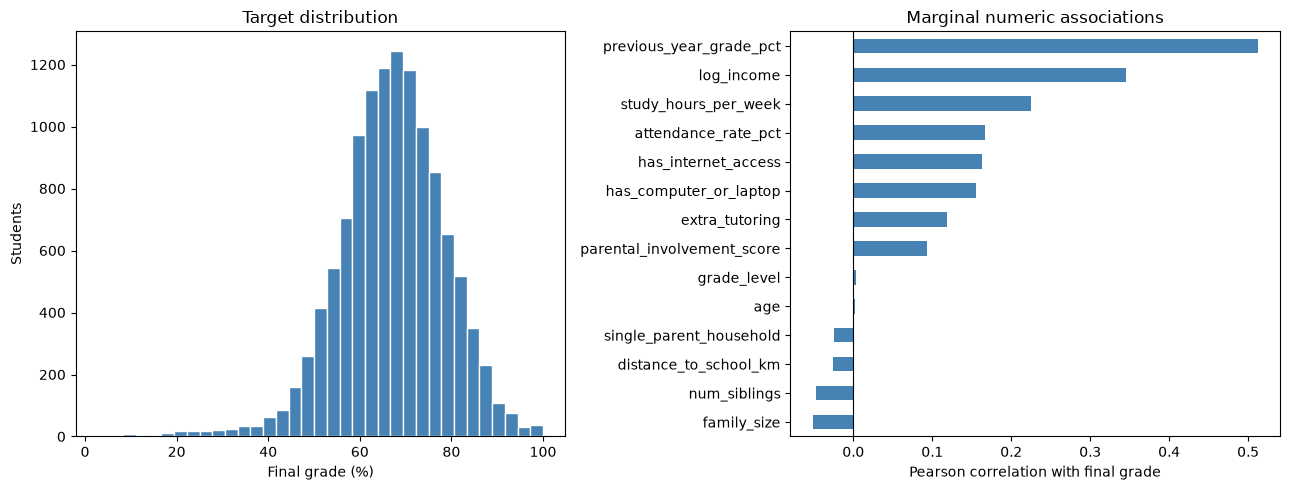

In [3]:
print("Most-missing predictors (fraction of students):")
print(X.isna().mean().sort_values(ascending=False).head(10).round(3).to_string())
print("\nTarget summary:")
print(y.describe().round(2).to_string())

target_corr = X[NUMERIC_COLS].corrwith(y).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(y, bins=35, color="steelblue", edgecolor="white")
axes[0].set(xlabel="Final grade (%)", ylabel="Students", title="Target distribution")
target_corr.plot.barh(ax=axes[1], color="steelblue")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Pearson correlation with final grade",
            title="Marginal numeric associations")
plt.tight_layout()
plt.show()


## Split and fold-local preprocessing

Numeric gaps use a median; categorical gaps use a mode; categories are one-hot encoded with one reference level dropped. The preprocessor is newly fitted for every inner or outer training fold. An unseen validation category is encoded as the reference level, so its interpretation is limited. No target-driven feature selection occurs before cross-validation.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=df["grade_class"],
    random_state=SEED,
)
print("Training:", X_train.shape, "| test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("numeric", SimpleImputer(strategy="median"), NUMERIC_COLS),
            ("categorical", make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
            ), CATEGORICAL_COLS),
        ],
        verbose_feature_names_out=False,
    )

def make_gam(n_features, smooth_lambda):
    # Continuous columns are first by construction. All remaining terms are linear;
    # one-hot coefficients represent category differences from a reference level.
    terms = None
    for j in range(n_features):
        term = (s(j, n_splines=10, lam=smooth_lambda)
                if j < len(CONTINUOUS_COLS) else l(j, lam=0))
        terms = term if terms is None else terms + term
    return LinearGAM(terms, max_iter=100, tol=1e-4)


Training: (10200, 24) | test: (1800, 24)


## Tune smoothness inside cross-validation

PyGAM's smoothing penalty controls how wiggly each continuous effect can be. The six candidate values share one penalty across all five smooth terms to keep the search small. Inner-fold RMSE selects the largest penalty within one standard error of the lowest mean RMSE, favoring a smoother fit when performance is similar. The factor and discrete terms remain unpenalized here; this is a modeling limitation to revisit if those effects are unstable.

The choice is conditional on this finite grid. A boundary value means the search has not identified a finite optimum.

In [5]:
def choose_smoothing_lambda(X_fit, y_fit, penalty_grid=None):
    if penalty_grid is None:
        penalty_grid = SMOOTHING_GRID
    inner = KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    prepared_folds = []
    for fit_idx, valid_idx in inner.split(X_fit):
        X_inner_fit, X_inner_valid = X_fit.iloc[fit_idx], X_fit.iloc[valid_idx]
        y_inner_fit, y_inner_valid = y_fit.iloc[fit_idx], y_fit.iloc[valid_idx]
        prep = make_preprocessor()
        Z_fit = prep.fit_transform(X_inner_fit)
        Z_valid = prep.transform(X_inner_valid)
        prepared_folds.append((Z_fit, Z_valid, y_inner_fit.to_numpy(),
                               y_inner_valid.to_numpy()))

    rows = []
    for lam in penalty_grid:
        train_errors, valid_errors = [], []
        for Z_fit, Z_valid, y_fit_fold, y_valid_fold in prepared_folds:
            model = make_gam(Z_fit.shape[1], lam).fit(Z_fit, y_fit_fold)
            train_errors.append(root_mean_squared_error(
                y_fit_fold, model.predict(Z_fit)))
            valid_errors.append(root_mean_squared_error(
                y_valid_fold, model.predict(Z_valid)))
        rows.append({"lambda": float(lam),
                     "mean_train_rmse": np.mean(train_errors),
                     "mean_rmse": np.mean(valid_errors),
                     "se_rmse": np.std(valid_errors, ddof=1) / np.sqrt(INNER_SPLITS)})
    scores = pd.DataFrame(rows)
    best = scores.loc[scores["mean_rmse"].idxmin()]
    eligible = scores.loc[
        scores["mean_rmse"] <= best["mean_rmse"] + best["se_rmse"], "lambda"
    ]
    return float(eligible.max()), scores


## Paired outer-fold comparison

Every model sees the same five validation folds and the same fold-fitted imputation and encoding. The forest is a **fixed-settings reference**, not a newly optimized forest. Its hyperparameters are displayed below; do not call it the best possible forest. Fold errors share training observations, so their spread and differences are descriptive rather than independent-sample significance tests.


In [6]:
FOREST_SETTINGS = dict(
    n_estimators=120, min_samples_leaf=10, max_features=0.7, n_jobs=-1,
)
outer_cv = KFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=SEED)
cv_rows = []
selected_lambdas = []

for fold, (fit_idx, valid_idx) in enumerate(outer_cv.split(X_train), start=1):
    X_fit, X_valid = X_train.iloc[fit_idx], X_train.iloc[valid_idx]
    y_fit, y_valid = y_train.iloc[fit_idx], y_train.iloc[valid_idx]
    lam, inner_scores = choose_smoothing_lambda(X_fit, y_fit)
    selected_lambdas.append(lam)

    prep = make_preprocessor()
    Z_fit = prep.fit_transform(X_fit)
    Z_valid = prep.transform(X_valid)
    models = {
        "Mean only": DummyRegressor(strategy="mean"),
        "OLS": LinearRegression(),
        "Random forest (reference)": RandomForestRegressor(
            **FOREST_SETTINGS, random_state=SEED + fold),
        "GAM": make_gam(Z_fit.shape[1], lam),
    }
    for name, model in models.items():
        model.fit(Z_fit, y_fit.to_numpy())
        score = root_mean_squared_error(y_valid, model.predict(Z_valid))
        cv_rows.append({"fold": fold, "model": name, "rmse": score})
    print(f"Outer fold {fold}/{OUTER_SPLITS}: GAM lambda={lam:g}")

cv_scores = pd.DataFrame(cv_rows)
print("\nGAM smoothing penalties by outer fold:", selected_lambdas)


Outer fold 1/5: GAM lambda=1e+06


Outer fold 2/5: GAM lambda=1e+06


Outer fold 3/5: GAM lambda=1e+06


Outer fold 4/5: GAM lambda=1e+06


Outer fold 5/5: GAM lambda=1e+06

GAM smoothing penalties by outer fold: [1000000.0, 1000000.0, 1000000.0, 1000000.0, 1000000.0]


                           mean_rmse  sd_rmse
model                                        
OLS                            9.629    0.215
GAM                            9.629    0.215
Random forest (reference)      9.831    0.198
Mean only                     11.697    0.090
GAM minus OLS: mean paired fold RMSE difference = +0.000
GAM minus Random forest (reference): mean paired fold RMSE difference = -0.202


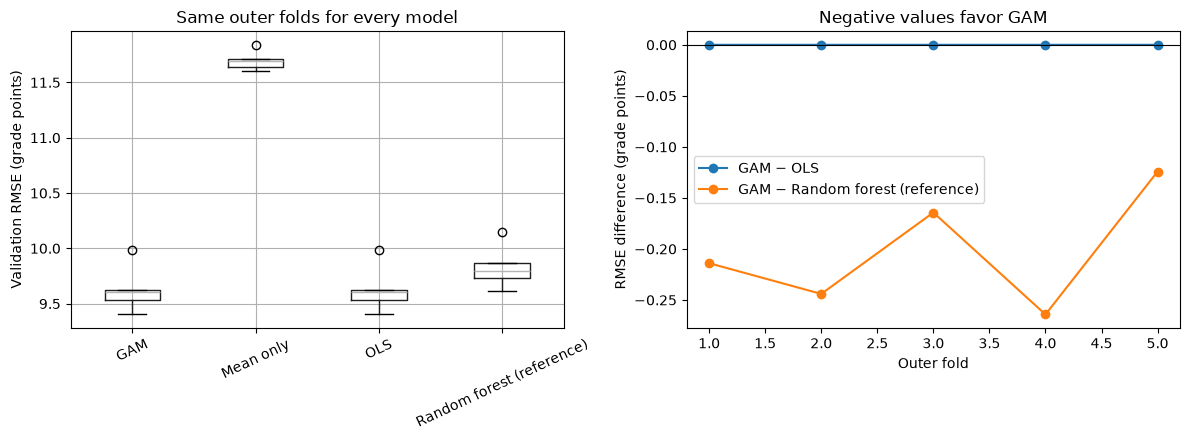

In [7]:
cv_wide = cv_scores.pivot(index="fold", columns="model", values="rmse")
cv_summary = (cv_scores.groupby("model")["rmse"]
              .agg(mean_rmse="mean", sd_rmse="std")
              .sort_values("mean_rmse"))
print(cv_summary.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cv_wide.boxplot(ax=axes[0], rot=25)
axes[0].set(ylabel="Validation RMSE (grade points)",
            title="Same outer folds for every model")
comparators = ["OLS", "Random forest (reference)"]
for name in comparators:
    diff = cv_wide["GAM"] - cv_wide[name]
    axes[1].plot(diff.index, diff.values, marker="o", label=f"GAM − {name}")
    print(f"GAM minus {name}: mean paired fold RMSE difference = {diff.mean():+.3f}")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Outer fold", ylabel="RMSE difference (grade points)",
            title="Negative values favor GAM")
axes[1].legend()
plt.tight_layout()
plt.show()


## Final fits and the shared test partition

Retune the GAM using training rows only, then refit each model on all training rows. The test partition is scored once per final model in this notebook. Because Project.ipynb already used this partition, report these scores as corroboration, not untouched confirmatory evidence.


Full-training inner-CV scores:
   lambda  mean_train_rmse  mean_rmse  se_rmse
      0.1            9.534      9.658    0.107
      1.0            9.537      9.649    0.107
     10.0            9.543      9.639    0.106
    100.0            9.548      9.635    0.106
   1000.0            9.552      9.632    0.105
  10000.0            9.554      9.630    0.104
1000000.0            9.554      9.630    0.104
Chosen GAM penalty within the original grid: 1e+06


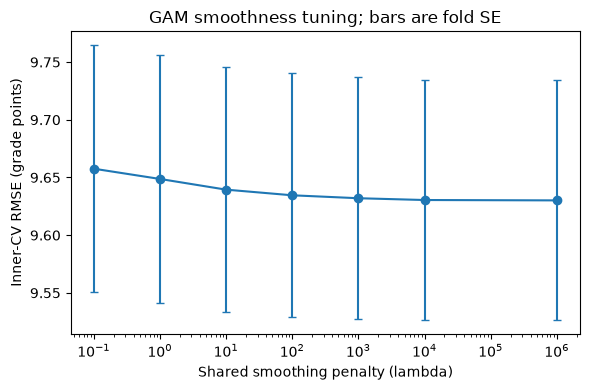


Test RMSE (grade points):
OLS                           9.813
GAM                           9.813
Random forest (reference)    10.032
Mean only                    11.708

Approximate effective degrees of freedom by smooth:
distance_to_school_km      2.13
study_hours_per_week       1.10
attendance_rate_pct        1.04
previous_year_grade_pct    1.07
log_income                 3.13


In [8]:
final_lambda, final_inner_scores = choose_smoothing_lambda(X_train, y_train)
print("Full-training inner-CV scores:")
print(final_inner_scores.round(3).to_string(index=False))
print(f"Chosen GAM penalty within the original grid: {final_lambda:g}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(final_inner_scores["lambda"], final_inner_scores["mean_rmse"],
            yerr=final_inner_scores["se_rmse"], marker="o", capsize=3)
ax.set_xscale("log")
ax.set(xlabel="Shared smoothing penalty (lambda)",
       ylabel="Inner-CV RMSE (grade points)",
       title="GAM smoothness tuning; bars are fold SE")
plt.tight_layout()
plt.show()

final_preprocessor = make_preprocessor()
Z_train = final_preprocessor.fit_transform(X_train)
Z_test = final_preprocessor.transform(X_test)
encoded_names = list(final_preprocessor.get_feature_names_out())
assert encoded_names[:len(CONTINUOUS_COLS)] == CONTINUOUS_COLS

final_models = {
    "Mean only": DummyRegressor(strategy="mean"),
    "OLS": LinearRegression(),
    "Random forest (reference)": RandomForestRegressor(
        **FOREST_SETTINGS, random_state=SEED),
    "GAM": make_gam(Z_train.shape[1], final_lambda),
}
test_predictions = {}
for name, model in final_models.items():
    model.fit(Z_train, y_train.to_numpy())
    test_predictions[name] = model.predict(Z_test)

test_rmse = pd.Series({
    name: root_mean_squared_error(y_test, pred)
    for name, pred in test_predictions.items()
}, name="test_rmse").sort_values()
print("\nTest RMSE (grade points):")
print(test_rmse.round(3).to_string())
gam_final = final_models["GAM"]
smooth_edf = pd.Series({
    name: gam_final.statistics_["edof_per_coef"][
        gam_final.terms.get_coef_indices(i)].sum()
    for i, name in enumerate(CONTINUOUS_COLS)
}, name="effective degrees of freedom")
print("\nApproximate effective degrees of freedom by smooth:")
print(smooth_edf.round(2).to_string())


### Does a larger smoothing penalty help?

The primary inner-CV grid ended at lambda = 10,000, so its boundary result cannot establish an optimum. As a **training-only sensitivity check**, repeat the same three inner folds for lambda values from 10,000 through 100 million. This check does not change the nested-CV model, the paired partial dependence comparison, or the held-out test result. Compare the size of any RMSE gain before treating a larger numerical lambda as a better practical model.

PyGAM penalizes the **second derivative** of each numerical spline ([PyGAM SplineTerm documentation](https://pygam.readthedocs.io/en/stable/reference/_autosummary/pygam.terms.SplineTerm.html)). As lambda becomes very large, each smooth approaches a straight line with a potentially nonzero slope. A horizontal line occurs only when the fitted slope is near zero.

The table and plot also show **training RMSE on each inner fit fold**, paired with validation RMSE on its held-out fold. A second-derivative penalty suppresses curvature as lambda grows. Near-straight smooths describe adjusted effects *within this fitted model*; they do not prove that each predictor has a marginal linear correlation with grade. In particular, log income is shown on its transformed scale, and the model does not include interactions.

On a flat validation curve, the one-standard-error rule picks the largest value **allowed by the grid**. Extending the grid would therefore move its choice upward without demonstrating a meaningful prediction gain. The large-lambda limit is an additive linear model on the encoded feature scale; compare it with the explicit OLS baseline on the same folds rather than assigning a numerical value to infinity. We retain lambda = 10,000 as a finite GAM illustration and use OLS when choosing a simpler prediction model.

Training-only inner-CV scores for larger smoothing penalties:
     lambda  mean_train_rmse  mean_rmse  se_rmse
    10000.0         9.553956   9.630473 0.104095
   100000.0         9.554381   9.630182 0.103932
  1000000.0         9.554430   9.630151 0.103914
 10000000.0         9.554435   9.630147 0.103912
100000000.0         9.554435   9.630145 0.103912
Best mean RMSE reduction beyond lambda = 10,000: 0.000328 grade points

Matched inner-fold training and validation RMSE:
     lambda  mean_train_rmse  mean_rmse
        0.1         9.534403   9.657612
        1.0         9.537375   9.648731
       10.0         9.542987   9.639461
      100.0         9.548123   9.634568
     1000.0         9.551932   9.632024
    10000.0         9.553956   9.630473
   100000.0         9.554381   9.630182
  1000000.0         9.554430   9.630151
 10000000.0         9.554435   9.630147
100000000.0         9.554435   9.630145

Same-fold OLS reference: training RMSE = 9.554435; validation RMSE = 9.630147


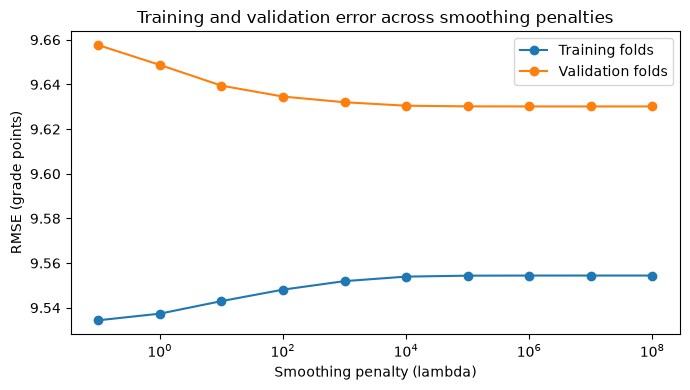

In [9]:
HIGH_PENALTY_GRID = np.array([1e4, 1e5, 1e6, 1e7, 1e8])
_, high_penalty_scores = choose_smoothing_lambda(
    X_train, y_train, penalty_grid=HIGH_PENALTY_GRID)
print("Training-only inner-CV scores for larger smoothing penalties:")
print(high_penalty_scores.round(6).to_string(index=False))
gain_beyond_10000 = (
    high_penalty_scores.iloc[0]["mean_rmse"]
    - high_penalty_scores["mean_rmse"].min()
)
print(f"Best mean RMSE reduction beyond lambda = 10,000: "
      f"{gain_beyond_10000:.6f} grade points")

combined_penalty_scores = (pd.concat([final_inner_scores, high_penalty_scores])
                           .drop_duplicates("lambda")
                           .sort_values("lambda"))
print("\nMatched inner-fold training and validation RMSE:")
print(combined_penalty_scores[["lambda", "mean_train_rmse", "mean_rmse"]]
      .round(6).to_string(index=False))
ols_train_errors, ols_valid_errors = [], []
inner_ols = KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
for fit_idx, valid_idx in inner_ols.split(X_train):
    prep = make_preprocessor()
    Z_fit = prep.fit_transform(X_train.iloc[fit_idx])
    Z_valid = prep.transform(X_train.iloc[valid_idx])
    y_fit = y_train.iloc[fit_idx].to_numpy()
    y_valid = y_train.iloc[valid_idx].to_numpy()
    ols = LinearRegression().fit(Z_fit, y_fit)
    ols_train_errors.append(root_mean_squared_error(y_fit, ols.predict(Z_fit)))
    ols_valid_errors.append(root_mean_squared_error(y_valid, ols.predict(Z_valid)))
print(f"\nSame-fold OLS reference: training RMSE = {np.mean(ols_train_errors):.6f}; "
      f"validation RMSE = {np.mean(ols_valid_errors):.6f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(combined_penalty_scores["lambda"],
        combined_penalty_scores["mean_train_rmse"],
        marker="o", label="Training folds")
ax.plot(combined_penalty_scores["lambda"],
        combined_penalty_scores["mean_rmse"],
        marker="o", label="Validation folds")
ax.set_xscale("log")
ax.set(xlabel="Smoothing penalty (lambda)",
       ylabel="RMSE (grade points)",
       title="Training and validation error across smoothing penalties")
ax.legend()
fig.tight_layout()
plt.show()


### Paired uncertainty on test performance

The interval below resamples test **students** while holding the fitted models fixed. It describes uncertainty in their paired RMSE difference on this test population. It does not include uncertainty from retraining, tuning, or having previously inspected this same test set. A negative GAM-minus-comparator difference favors the GAM.


                                 rmse_difference  ci_lower  ci_upper
comparison                                                          
GAM − OLS                                  0.000    -0.000     0.000
GAM − Random forest (reference)           -0.219    -0.316    -0.122


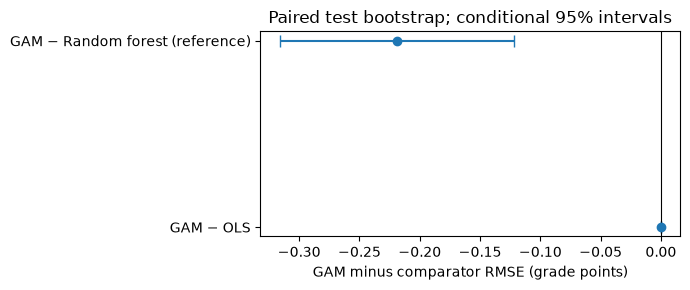

In [10]:
rng = np.random.default_rng(SEED)
test_y = y_test.to_numpy()
bootstrap_index = rng.integers(0, len(test_y), size=(1000, len(test_y)))
gam_squared_error = (test_y - test_predictions["GAM"]) ** 2

comparison_rows = []
for name in ["OLS", "Random forest (reference)"]:
    comparator_squared_error = (test_y - test_predictions[name]) ** 2
    boot_diff = (
        np.sqrt(gam_squared_error[bootstrap_index].mean(axis=1))
        - np.sqrt(comparator_squared_error[bootstrap_index].mean(axis=1))
    )
    comparison_rows.append({
        "comparison": f"GAM − {name}",
        "rmse_difference": test_rmse["GAM"] - test_rmse[name],
        "ci_lower": np.quantile(boot_diff, 0.025),
        "ci_upper": np.quantile(boot_diff, 0.975),
    })
comparison = pd.DataFrame(comparison_rows).set_index("comparison")
print(comparison.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3))
positions = np.arange(len(comparison))
ax.errorbar(
    comparison["rmse_difference"], positions,
    xerr=[comparison["rmse_difference"] - comparison["ci_lower"],
          comparison["ci_upper"] - comparison["rmse_difference"]],
    fmt="o", capsize=4,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(positions, comparison.index)
ax.set(xlabel="GAM minus comparator RMSE (grade points)",
       title="Paired test bootstrap; conditional 95% intervals")
plt.tight_layout()
plt.show()


## Partial dependence plots

Each figure compares the finite GAM chosen from the original grid (lambda = 10,000 in the verified run) with a more flexible fit at lambda = 0.1. Following the course GAM demo, these term-level partial dependence plots show additive contributions to predicted final grade in **percentage points**, with approximate **pointwise 95% model-based confidence limits** from PyGAM. The paired panels use the same feature range and y-axis scale. They are not intervals for individual grades and do not establish causal effects. All five continuous features modeled with smooth terms are shown. The horizontal range is restricted to the middle 90% of training values to avoid interpreting sparsely supported tails. PyGAM term effects include a vertical offset relative to the model intercept, so compare the shape and change across each x-axis rather than the absolute y-position between fits.

In [11]:
PLOT_SMOOTHS = [
    "previous_year_grade_pct", "log_income",
    "study_hours_per_week", "attendance_rate_pct",
    "distance_to_school_km",
]
axis_labels = {
    "previous_year_grade_pct": "Previous-year grade (%)",
    "log_income": "Log annual family income (INR)",
    "study_hours_per_week": "Study hours per week",
    "attendance_rate_pct": "Attendance rate (%)",
    "distance_to_school_km": "Distance to school (km)",
}
term_labels = {
    "previous_year_grade_pct": "previous-year grade",
    "log_income": "log income",
    "study_hours_per_week": "study hours",
    "attendance_rate_pct": "attendance rate",
    "distance_to_school_km": "distance to school",
}
base_row = np.median(Z_train, axis=0)

def plot_gam_comparison(gam_low, gam_selected, low_lambda, selected_lambda):
    models = [(low_lambda, gam_low), (selected_lambda, gam_selected)]
    for name in PLOT_SMOOTHS:
        term_index = encoded_names.index(name)
        lo, hi = np.quantile(Z_train[:, term_index], [0.05, 0.95])
        grid = np.tile(base_row, (120, 1))
        grid[:, term_index] = np.linspace(lo, hi, len(grid))
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)
        for ax, (smooth_lambda, gam_model) in zip(axes, models):
            effect, interval = gam_model.partial_dependence(
                term=term_index, X=grid, width=0.95)
            ax.plot(grid[:, term_index], effect, color="navy")
            ax.plot(grid[:, term_index], interval, color="red",
                    linestyle="--", linewidth=1)
            ax.set(xlabel=axis_labels[name],
                   title=f"{repr(gam_model.terms[term_index])}; lambda = {smooth_lambda:g}")
        axes[0].set_ylabel(
            f"Partial dependence of final grade on {term_labels[name]} (points)")
        fig.tight_layout()
        plt.show()


### Smoothing comparison

Fit the lambda = 0.1 GAM on the **same training rows and preprocessing**. Each feature appears in one figure, with the weaker penalty on the left and the lambda = 10,000 penalty on the right. Blue curves are fitted effects; red dashed curves are approximate pointwise 95% model-based confidence limits. The lambda = 0.1 fit is a sensitivity check and is not used to select the test-set result.

Approximate effective degrees of freedom by smooth:
                         lambda = 0.1  lambda = 1e+06
distance_to_school_km            8.55            2.13
study_hours_per_week             6.79            1.10
attendance_rate_pct              7.94            1.04
previous_year_grade_pct          7.46            1.07
log_income                       7.80            3.13

Inner-CV mean RMSE by smoothing penalty:
   lambda  mean_rmse  se_rmse
      0.1      9.658    0.107
1000000.0      9.630    0.104


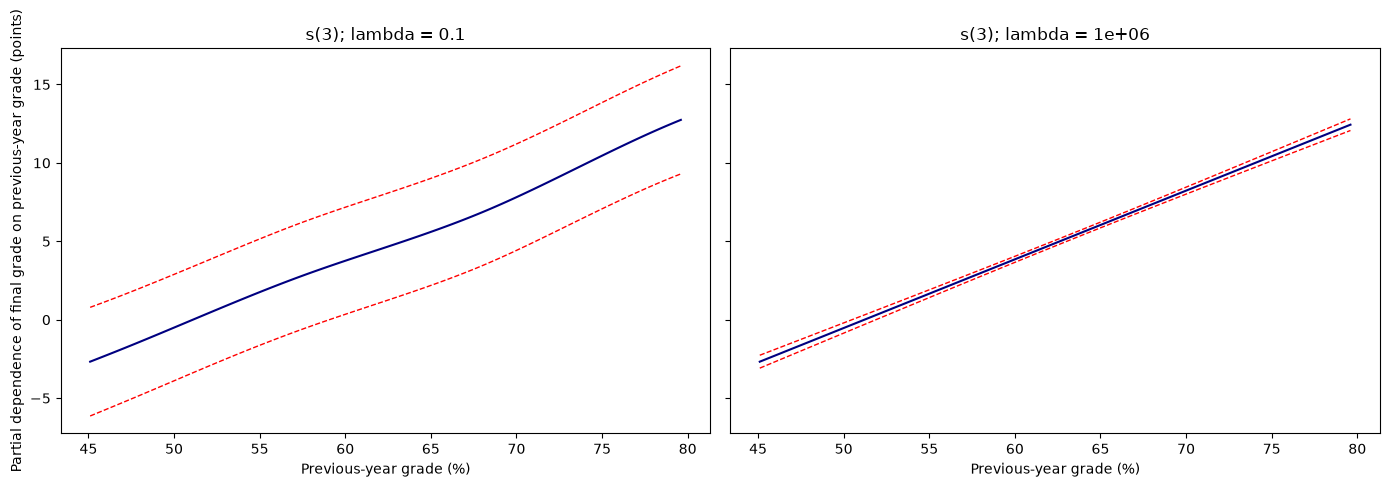

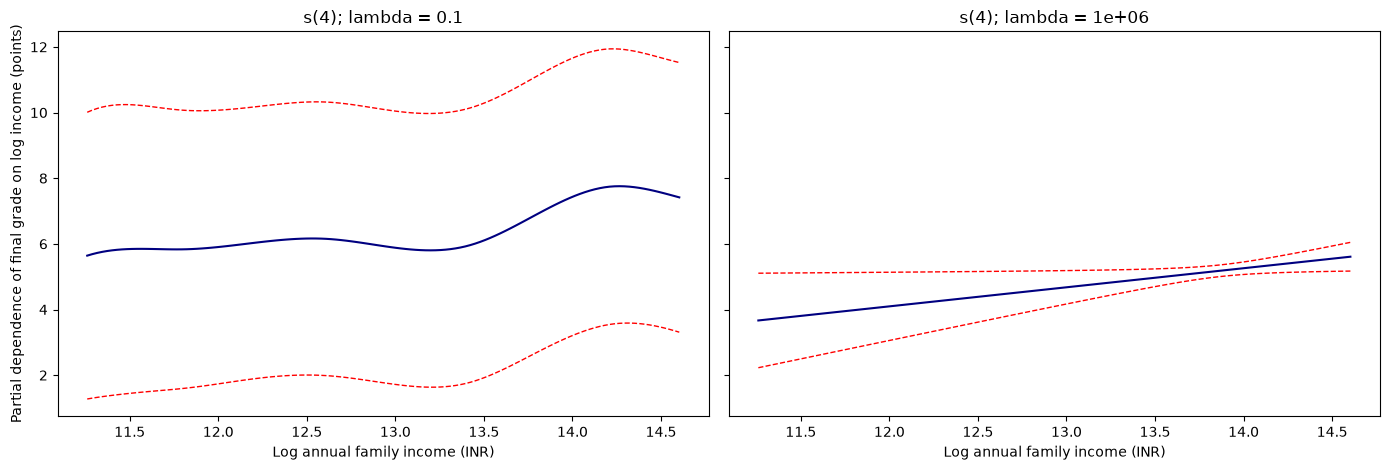

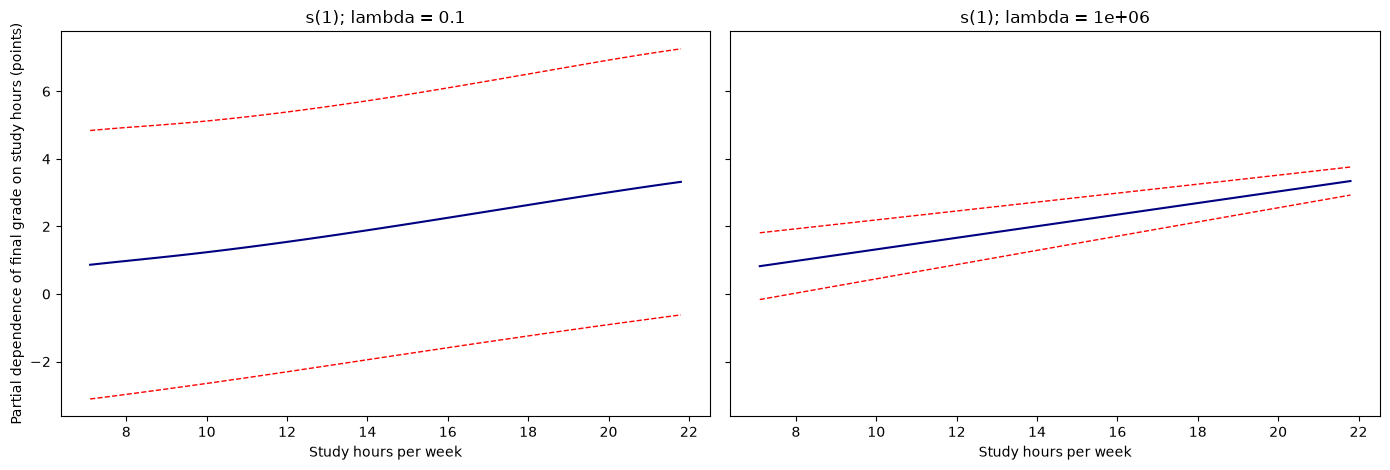

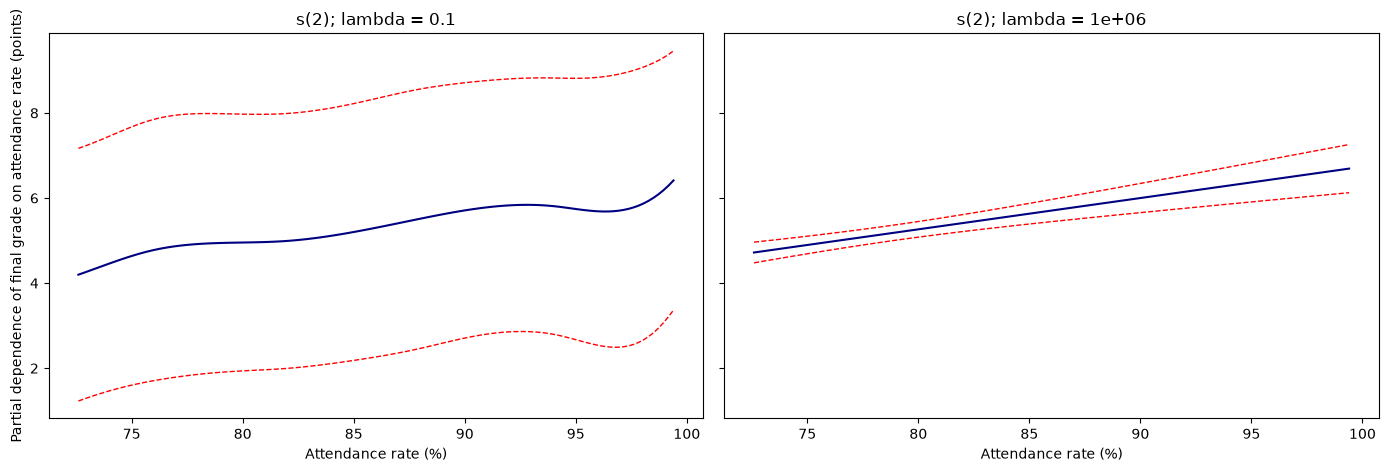

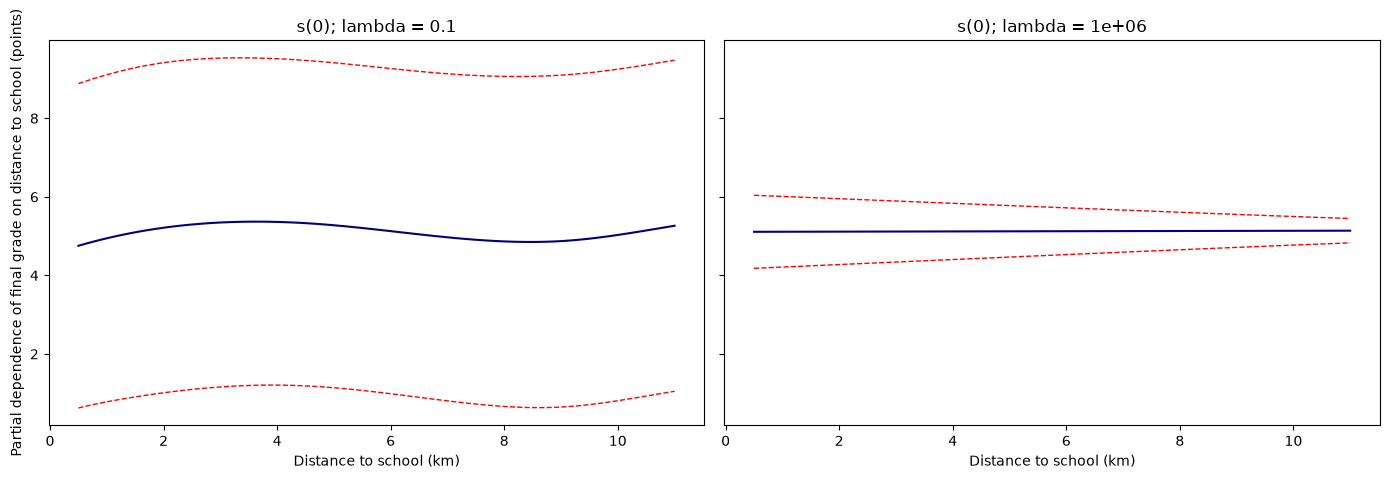

In [12]:
LOW_SMOOTHING_LAMBDA = 0.1
gam_low_smoothing = make_gam(Z_train.shape[1], LOW_SMOOTHING_LAMBDA)
gam_low_smoothing.fit(Z_train, y_train.to_numpy())

edf_low = pd.Series({
    name: gam_low_smoothing.statistics_["edof_per_coef"][
        gam_low_smoothing.terms.get_coef_indices(i)].sum()
    for i, name in enumerate(CONTINUOUS_COLS)
}, name="lambda = 0.1")
print("Approximate effective degrees of freedom by smooth:")
print(pd.concat([edf_low, smooth_edf.rename(f"lambda = {final_lambda:g}")], axis=1).round(2).to_string())
print("\nInner-CV mean RMSE by smoothing penalty:")
print(final_inner_scores.loc[
    final_inner_scores["lambda"].isin([LOW_SMOOTHING_LAMBDA, final_lambda]),
    ["lambda", "mean_rmse", "se_rmse"],
].round(3).to_string(index=False))
plot_gam_comparison(
    gam_low_smoothing, gam_final, LOW_SMOOTHING_LAMBDA, final_lambda)


At lambda = 0.1, the smooth terms use roughly 6.8 to 8.6 effective degrees of freedom and show more wiggle than the selected fit. The inner-CV mean RMSE is **9.658** versus **9.630** for lambda = 10,000. The weaker-penalty curves illustrate sensitivity to regularization; the cross-validated fit is used for the held-out test comparison.

### An adjusted categorical contrast

For scholarship status, set that category to each observed level for the **same** sampled training students and average the GAM predictions. Additivity makes these level differences constant across students in this model. They are adjusted predictive associations, not causal effects; the table omits uncertainty for these contrasts.


In [13]:
scholarship_levels = sorted(X_train["scholarship_status"].dropna().unique())
template = X_train.sample(n=min(1000, len(X_train)), random_state=SEED).copy()
adjusted_predictions = {}
for level in scholarship_levels:
    changed = template.copy()
    changed["scholarship_status"] = level
    adjusted_predictions[level] = gam_final.predict(
        final_preprocessor.transform(changed)).mean()
reference_level = scholarship_levels[0]
scholarship_effects = pd.Series({
    level: value - adjusted_predictions[reference_level]
    for level, value in adjusted_predictions.items()
}, name=f"predicted grade difference vs {reference_level} (points)")
print(scholarship_effects.round(3).to_string())


Full              0.000
No Scholarship   -3.602
Partial          -2.009


## Diagnostics and report interpretation

A residual pattern can reveal structure the additive model misses. Use the CV and test tables, smooth plots, and limitations together:

- GAM below OLS in paired RMSE supports useful nonlinear additive structure; similar scores suggest linear effects may suffice.
- A forest advantage could reflect interactions or other flexibility. These models alone cannot isolate the cause.
- Report the magnitude of differences and uncertainty, the chosen smoothing penalty, important smooths, and the cost of choosing the interpretable model.
- The fixed forest is a reference, the five CV folds overlap in training rows, one shared smoothing penalty may miss feature-specific complexity, one-hot category levels may be sparse, and the test set has already been examined in the main notebook.
- Keep the report concise. Check the rubric separately for its unsupervised-analysis criterion.


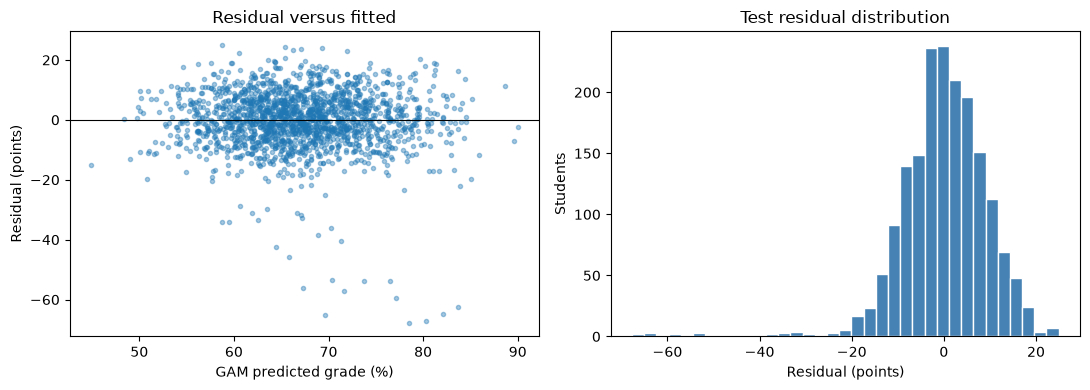

Mean test residual: -0.138 points


In [14]:
gam_residual = test_y - test_predictions["GAM"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(test_predictions["GAM"], gam_residual, s=9, alpha=0.4)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="GAM predicted grade (%)", ylabel="Residual (points)",
            title="Residual versus fitted")
axes[1].hist(gam_residual, bins=35, color="steelblue", edgecolor="white")
axes[1].set(xlabel="Residual (points)", ylabel="Students",
            title="Test residual distribution")
plt.tight_layout()
plt.show()
print(f"Mean test residual: {gam_residual.mean():+.3f} points")


## Findings from the verified run

**Large-penalty conclusion.** In this Gaussian additive GAM, as lambda approaches infinity, the second-derivative penalty removes curvature from the spline terms. Each smooth approaches a straight line, which may still have a nonzero slope; the remaining terms are already linear. The model therefore approaches OLS on the **same preprocessed predictors**. Once validation error has plateaued, use OLS directly for prediction instead of increasing lambda without bound. This limiting result does not imply that every raw predictor has a marginal linear relationship with grade.

Across five paired outer folds, GAM and OLS both have mean RMSE about **9.629 grade points**; the fixed-settings forest has **9.831** and the mean-only baseline **11.697**. The original bounded search chose **10,000** in every outer fold; this is a grid-limited choice, not a global optimum. An extra training-only search through lambda = 100 million reduces inner-CV mean RMSE by just **0.000328 grade points** beyond lambda = 10,000, so the score has effectively plateaued. At lambda = 100 million, inner-CV validation RMSE is **9.630145**, nearly identical to **9.630147** for OLS on the same folds. The GAM gives no useful predictive gain over OLS here. Across matched inner folds, mean training RMSE rises from **9.534** at lambda = 0.1 to **9.554** at lambda = 100 million, while validation RMSE falls from **9.658** to **9.630**. This is consistent with weaker regularization fitting the training folds slightly better but generalizing slightly worse. Near-straight smooths do not establish marginal linear correlation or causality; they are adjusted effects under this additive model and its chosen penalty. Some fitted smooths still have more than one effective degree of freedom, especially log income and distance to school, so similar prediction error does not prove every relationship is exactly linear.

On the shared test partition, GAM RMSE is **9.814**, OLS **9.813**, and the reference forest **10.032**. The paired test bootstrap puts GAM minus forest RMSE at about **−0.218** points, with a conditional 95% interval of **[−0.316, −0.122]**; GAM minus OLS is essentially zero. These intervals hold the fitted models fixed, and this test partition was already inspected in Project.ipynb. Prefer the simpler OLS model if prediction is the only goal; the GAM adds readable smooth-effect plots at virtually the same error. Re-run the notebook if the data, feature choices, or environment changes.
